# Visualização Executiva: Benchmarking Biométrico & Extrapolação de Talhões

Este notebook consolida e apresenta todos os resultados do pipeline biométrico automatizado (`run_biometric_framework.py`).

---

## Diagrama do Pipeline Metodológico

```
┌────────────────────────────────────────────────────────────────────────────────────────┐
│                                PIPELINE BIOMÉTRICO LIDAR                                │
└────────────────────────────────────────────────────────────────────────────────────────┘
                                             │
               ┌─────────────────────────────┴─────────────────────────────┐
               ▼                                                           ▼
     [ Talhão 62 — 5 cm ]                                        [ Talhão 37 — 10 cm ]
    4 Parcelas (500,503,508,509)                               11 Parcelas (594 a 648)
               │                                                           │
               ├─► 1. Refinamento de Tronco (KDTree Cylinder-Following) ───┤
               │      Reatribui pontos de fuste não associados             │
               │                                                           │
               ├─► 2. Pareamento Espacial Adaptativo com Inventário ───────┤
               │      Alinhamento de grade + consenso biométrico           │
               │      (43 árvores T62 / 155 árvores T37 com Ground Truth)  │
               │                                                           │
               ├─► 3. Grid Search Multi-Método (Volume & DAP) ─────────────┤
               │      • Voxel: voxel_size ∈ [0.06, 0.07, 0.08, 0.09, 0.10] │
               │      • Axis Profile: fatias (15, 20) x percentis (15-25%) │
               │      • Cilindro Calibrado: f_factor ∈ [0.35, ..., 0.45]   │
               │                                                           │
               └─────────────────────────────┬─────────────────────────────┘
                                             │
               ┌─────────────────────────────┴─────────────────────────────┐
               ▼                                                           ▼
      [ Modo 1: Global Best ]                                  [ Modo 2: Human in Loop ]
   Melhor parametrização fixa                               Seleção da parametrização ideal
   minimizando erro agregado                                para cada árvore individualmente
               │                                                           │
               └─────────────────────────────┬─────────────────────────────┘
                                             │
                                             ▼
                         [ Avaliação por Parcela & Extrapolação ]
                         • Volume por hectare (m³/ha) vs Oficial
                         • Extrapolação para toda a área dos talhões
```

In [3]:
import os, sys
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir(os.path.abspath(os.path.join(os.getcwd(), "../..")))
if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())

import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configurações estéticas
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.size"] = 10

DATA_DIR = "/mnt/scratch/keiller/projeto_eucalipto/biometric_bench_output/sat_ff3d/"
df_trees_t62 = pd.read_csv(os.path.join(DATA_DIR, "df_trees_t62.csv"))
df_trees_t37 = pd.read_csv(os.path.join(DATA_DIR, "df_trees_t37.csv"))
df_plots = pd.read_csv(os.path.join(DATA_DIR, "df_plots_summary.csv"))
df_extrap = pd.read_csv(os.path.join(DATA_DIR, "df_extrapolation_summary.csv"))

with open(os.path.join(DATA_DIR, "metrics_summary.json"), "r") as f:
    metrics_json = json.load(f)

print(f"Dados carregados: {len(df_trees_t62)} árvores T62, {len(df_trees_t37)} árvores T37, {len(df_plots)} parcelas avaliadas.")

Dados carregados: 43 árvores T62, 171 árvores T37, 15 parcelas avaliadas.


## 1. Análise Comparativa por Método de Volume

Abaixo avaliamos o desempenho de cada família volumétrica e suas parametrizações:
* **`voxel`**: Quantização discreta 3D do fuste (`voxel_size` entre 0.06m e 0.10m);
* **`axis_profile`**: Fatiamento vertical com integração trapezoidal de raios percentis;
* **`cyl_ff`**: Cilindro dendrométrico corrigido pelo fator de forma empírico ($f \in [0.35, 0.45]$).

╔══════════════════════════════════════════════════════════════════════════════════════════════════════════════╗
║                             MELHOR CONFIGURAÇÃO POR MÉTODO DE VOLUME                                          ║
╚══════════════════════════════════════════════════════════════════════════════════════════════════════════════╝


,Talhão Base,Família de Método,Melhor Config,RMSE (m³),MAE (m³),Viés (%),Média Est (m³),Média GT (m³)
0,Talhão 37 (10 cm),Axis Profile,axis_rp15_ns15,3.5280,1.0394,+470.9%,1.092,0.191
1,Talhão 37 (10 cm),Cilindro (c/ Fator Forma),cyl_ff0.35,4.8331,2.3166,+1203.1%,2.485,0.191
2,Talhão 37 (10 cm),Voxel 3D,voxel_vs0.08,0.1476,0.1129,-32.8%,0.130,0.193
3,Talhão 62 (5 cm),Axis Profile,axis_rp15_ns15,3.8355,1.2396,+350.5%,1.366,0.303
4,Talhão 62 (5 cm),Cilindro (c/ Fator Forma),cyl_ff0.35,2.8067,1.6990,+526.9%,1.867,0.298
5,Talhão 62 (5 cm),Voxel 3D,voxel_vs0.08,0.2039,0.1678,-12.8%,0.263,0.301


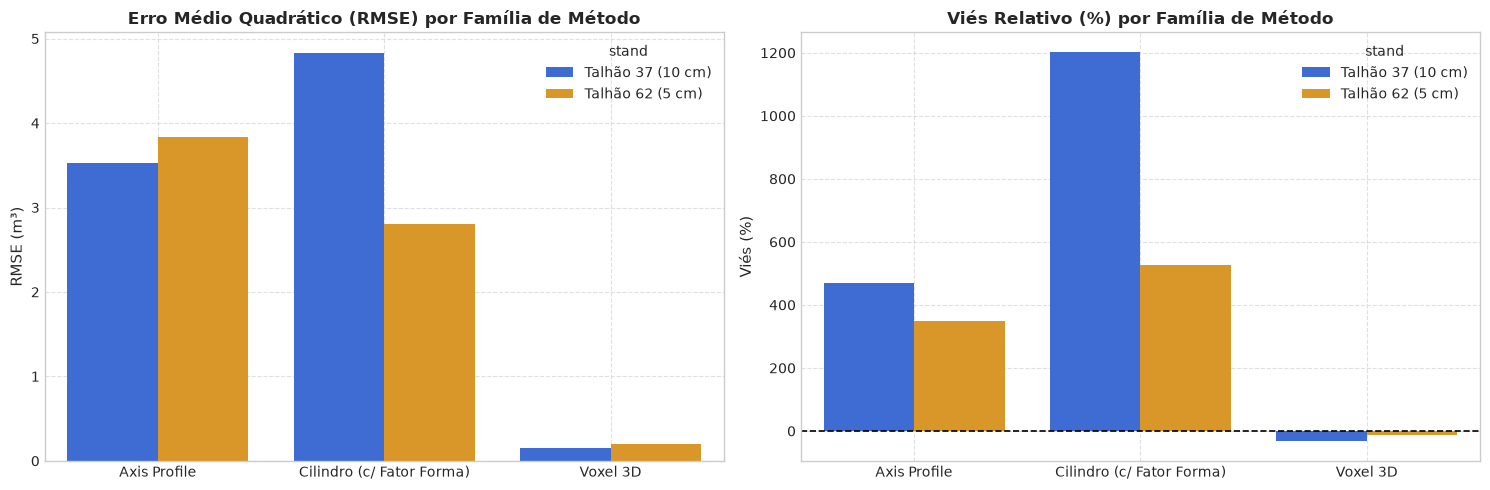

In [4]:
# 1. Construir DataFrame com o ranking completo de todos os métodos
df_cfg_t62 = pd.DataFrame(metrics_json["t62_base"]["cfg_ranking"])
df_cfg_t62["stand"] = "Talhão 62 (5 cm)"

df_cfg_t37 = pd.DataFrame(metrics_json["t37_base"]["cfg_ranking"])
df_cfg_t37["stand"] = "Talhão 37 (10 cm)"

def categorizar_metodo(cfg):
    if cfg.startswith("voxel"): return "Voxel 3D"
    if cfg.startswith("axis"): return "Axis Profile"
    if cfg.startswith("cyl"): return "Cilindro (c/ Fator Forma)"
    return "Outro"

df_cfg_all = pd.concat([df_cfg_t62, df_cfg_t37], ignore_index=True)
df_cfg_all["metodo_familia"] = df_cfg_all["config"].apply(categorizar_metodo)

# Tabela comparativa resumida: Melhor configuração de cada família
melhores_por_familia = df_cfg_all.sort_values("rmse_m3").groupby(["stand", "metodo_familia"]).first().reset_index()
tabela_metodos = melhores_por_familia[["stand", "metodo_familia", "config", "rmse_m3", "mae_m3", "bias_pct", "mean_est_m3", "mean_gt_m3"]].copy()
tabela_metodos.columns = ["Talhão Base", "Família de Método", "Melhor Config", "RMSE (m³)", "MAE (m³)", "Viés (%)", "Média Est (m³)", "Média GT (m³)"]
print("╔══════════════════════════════════════════════════════════════════════════════════════════════════════════════╗")
print("║                             MELHOR CONFIGURAÇÃO POR MÉTODO DE VOLUME                                          ║")
print("╚══════════════════════════════════════════════════════════════════════════════════════════════════════════════╝")
display(tabela_metodos.style.format({
    "RMSE (m³)": "{:.4f}", "MAE (m³)": "{:.4f}", "Viés (%)": "{:+.1f}%",
    "Média Est (m³)": "{:.3f}", "Média GT (m³)": "{:.3f}"
}))

# Gráfico comparativo de RMSE e Viés por Método em ambos os voos
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Gráfico A: RMSE por método
sns.barplot(data=melhores_por_familia, x="metodo_familia", y="rmse_m3", hue="stand", ax=axes[0], palette=["#2563eb", "#f59e0b"])
axes[0].set_title("Erro Médio Quadrático (RMSE) por Família de Método", fontsize=12, fontweight="bold")
axes[0].set_ylabel("RMSE (m³)", fontsize=11)
axes[0].set_xlabel("")
axes[0].grid(True, linestyle="--", alpha=0.6)

# Gráfico B: Viés (%) por método
sns.barplot(data=melhores_por_familia, x="metodo_familia", y="bias_pct", hue="stand", ax=axes[1], palette=["#2563eb", "#f59e0b"])
axes[1].axhline(0, color="black", linestyle="--", lw=1.2)
axes[1].set_title("Viés Relativo (%) por Família de Método", fontsize=12, fontweight="bold")
axes[1].set_ylabel("Viés (%)", fontsize=11)
axes[1].set_xlabel("")
axes[1].grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()

## 2. Dispersão 1:1 por Árvore — Global vs Human-in-the-Loop
Compara a estimativa volumétrica individual de cada fuste contra a cubagem real de campo (Ground Truth).

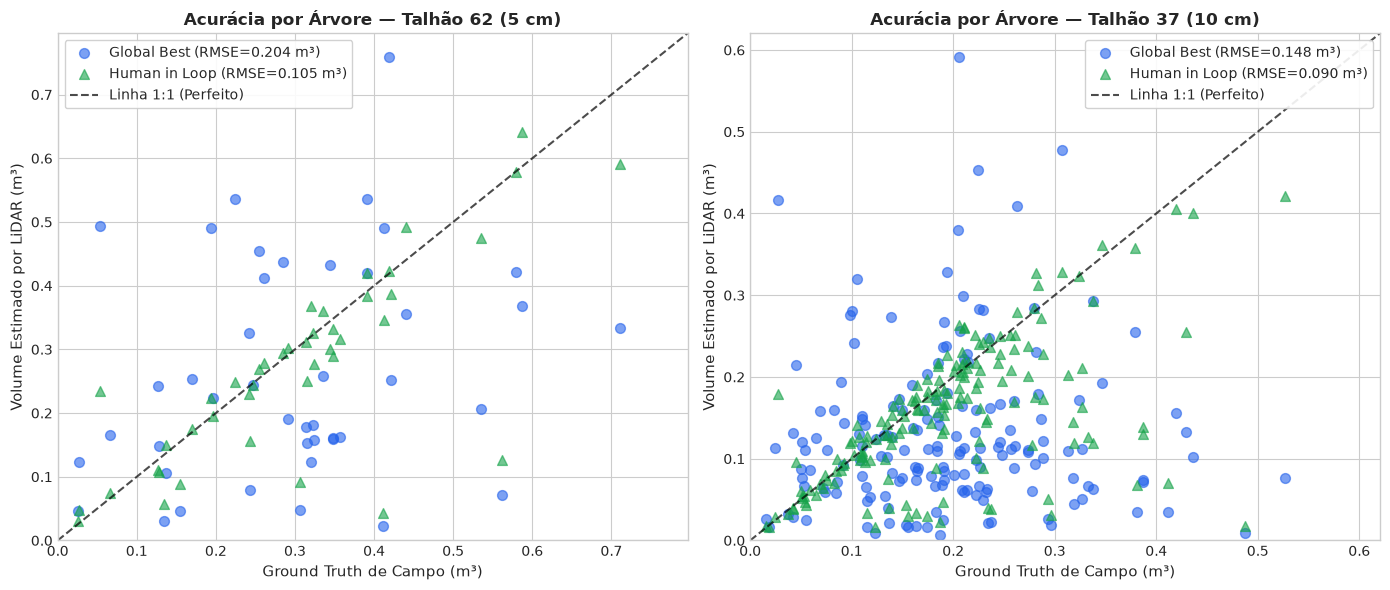

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, (df_t, name, rmse_g, rmse_h) in zip(axes, [
    (df_trees_t62, "Talhão 62 (5 cm)", metrics_json["t62_base"]["global_rmse_m3"], metrics_json["t62_base"]["human_rmse_m3"]),
    (df_trees_t37, "Talhão 37 (10 cm)", metrics_json["t37_base"]["global_rmse_m3"], metrics_json["t37_base"]["human_rmse_m3"])
]):
    gt = df_t["gt_volume"]
    g_est = df_t["vol_global_best"]
    h_est = df_t["vol_human_in_loop"]
    
    ax.scatter(gt, g_est, color="#2563eb", alpha=0.6, s=50, label=f"Global Best (RMSE={rmse_g:.3f} m³)")
    ax.scatter(gt, h_est, color="#16a34a", alpha=0.6, s=50, marker="^", label=f"Human in Loop (RMSE={rmse_h:.3f} m³)")
    
    lims = [0, max(gt.max(), g_est.max(), h_est.max()) * 1.05]
    ax.plot(lims, lims, "k--", lw=1.5, alpha=0.7, label="Linha 1:1 (Perfeito)")
    ax.set_xlim(lims); ax.set_ylim(lims)
    ax.set_title(f"Acurácia por Árvore — {name}", fontsize=12, fontweight="bold")
    ax.set_xlabel("Ground Truth de Campo (m³)", fontsize=11)
    ax.set_ylabel("Volume Estimado por LiDAR (m³)", fontsize=11)
    ax.legend(frameon=True, facecolor="white", framealpha=0.9)

plt.tight_layout()
plt.show()

### Tabela Síntese: Ganho da Abordagem Human-in-the-Loop por Árvore

In [6]:
df_tree_summary = pd.DataFrame([
    {
        "Base de Calibração": "Talhão 62 (5 cm)",
        "Árvores Pareadas": metrics_json["t62_base"]["n_trees_eval"],
        "Melhor Config Global": metrics_json["t62_base"]["best_global_config"],
        "RMSE Global (m³)": metrics_json["t62_base"]["global_rmse_m3"],
        "RMSE Human (m³)": metrics_json["t62_base"]["human_rmse_m3"],
        "Redução Erro (%)": (metrics_json["t62_base"]["human_rmse_m3"] - metrics_json["t62_base"]["global_rmse_m3"]) / metrics_json["t62_base"]["global_rmse_m3"] * 100,
        "Viés Global (%)": metrics_json["t62_base"]["global_bias_pct"],
        "Viés Human (%)": metrics_json["t62_base"]["human_bias_pct"],
    },
    {
        "Base de Calibração": "Talhão 37 (10 cm)",
        "Árvores Pareadas": metrics_json["t37_base"]["n_trees_eval"],
        "Melhor Config Global": metrics_json["t37_base"]["best_global_config"],
        "RMSE Global (m³)": metrics_json["t37_base"]["global_rmse_m3"],
        "RMSE Human (m³)": metrics_json["t37_base"]["human_rmse_m3"],
        "Redução Erro (%)": (metrics_json["t37_base"]["human_rmse_m3"] - metrics_json["t37_base"]["global_rmse_m3"]) / metrics_json["t37_base"]["global_rmse_m3"] * 100,
        "Viés Global (%)": metrics_json["t37_base"]["global_bias_pct"],
        "Viés Human (%)": metrics_json["t37_base"]["human_bias_pct"],
    }
])

display(df_tree_summary.style.format({
    "RMSE Global (m³)": "{:.4f}", "RMSE Human (m³)": "{:.4f}",
    "Redução Erro (%)": "{:+.1f}%", "Viés Global (%)": "{:+.1f}%", "Viés Human (%)": "{:+.1f}%"
}))

,Base de Calibração,Árvores Pareadas,Melhor Config Global,RMSE Global (m³),RMSE Human (m³),Redução Erro (%),Viés Global (%),Viés Human (%)
0,Talhão 62 (5 cm),43,voxel_vs0.08,0.2039,0.1049,-48.6%,-12.8%,-10.1%
1,Talhão 37 (10 cm),171,voxel_vs0.08,0.1476,0.0903,-38.8%,-32.8%,-19.9%


## 3. Erro de Volumetria por Parcela (m³/ha)
Avaliação parcela a parcela do erro relativo frente ao inventário oficial.

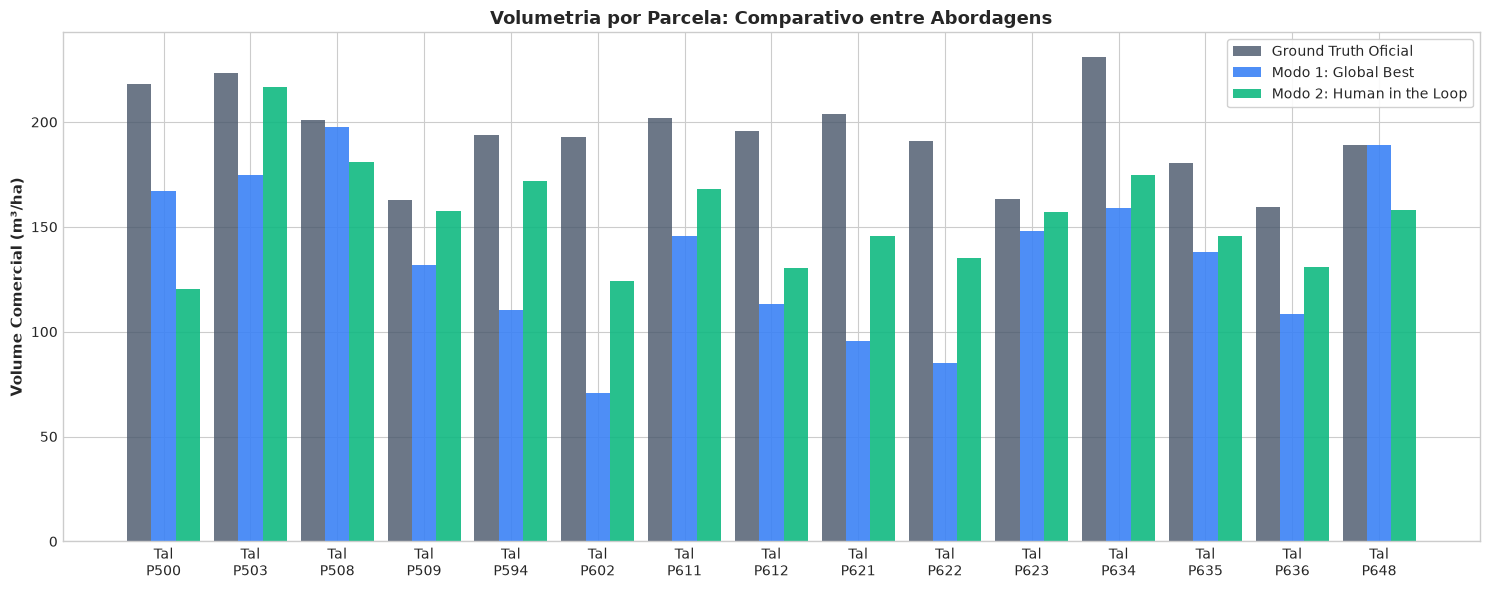

In [7]:
fig, ax = plt.subplots(figsize=(15, 6))

x = np.arange(len(df_plots))
width = 0.28

b1 = ax.bar(x - width, df_plots["gt_m3_ha"], width, label="Ground Truth Oficial", color="#475569", alpha=0.8)
b2 = ax.bar(x, df_plots["global_m3_ha"], width, label="Modo 1: Global Best", color="#3b82f6", alpha=0.9)
b3 = ax.bar(x + width, df_plots["human_m3_ha"], width, label="Modo 2: Human in the Loop", color="#10b981", alpha=0.9)

labels = [f"{row.stand[:3]}\nP{int(row.plot_id)}" for _, row in df_plots.iterrows()]
ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=10)
ax.set_ylabel("Volume Comercial (m³/ha)", fontsize=11, fontweight="bold")
ax.set_title("Volumetria por Parcela: Comparativo entre Abordagens", fontsize=13, fontweight="bold")
ax.legend(frameon=True, facecolor="white", framealpha=0.9)

plt.tight_layout()
plt.show()

### Tabela Síntese: Resultados por Parcela Individual

In [8]:
tab_plots = df_plots[["stand", "plot_id", "n_matched", "n_living_field", "gt_m3_ha", "global_m3_ha", "global_err_pct", "human_m3_ha", "human_err_pct"]].copy()
tab_plots.columns = ["Talhão", "Parcela", "Árvores Pareadas", "Árvores Vivas", "GT Oficial (m³/ha)", "Global (m³/ha)", "Erro Global (%)", "Human (m³/ha)", "Erro Human (%)"]
display(tab_plots.style.format({
    "GT Oficial (m³/ha)": "{:.1f}", "Global (m³/ha)": "{:.1f}", "Erro Global (%)": "{:+.1f}%",
    "Human (m³/ha)": "{:.1f}", "Erro Human (%)": "{:+.1f}%"
}))

,Talhão,Parcela,Árvores Pareadas,Árvores Vivas,GT Oficial (m³/ha),Global (m³/ha),Erro Global (%),Human (m³/ha),Erro Human (%)
0,Talhão 62 (5cm),500,8,28,218.3,167.1,-23.5%,120.4,-44.9%
1,Talhão 62 (5cm),503,11,28,223.4,174.8,-21.7%,216.8,-3.0%
2,Talhão 62 (5cm),508,16,33,200.7,197.7,-1.5%,180.9,-9.9%
3,Talhão 62 (5cm),509,8,15,162.7,131.7,-19.0%,157.5,-3.2%
4,Talhão 37 (10cm),594,17,41,193.9,110.5,-43.0%,172.0,-11.3%
5,Talhão 37 (10cm),602,9,36,192.9,70.6,-63.4%,123.9,-35.7%
6,Talhão 37 (10cm),611,17,41,202.1,145.5,-28.0%,168.2,-16.8%
7,Talhão 37 (10cm),612,16,45,195.8,113.2,-42.2%,130.5,-33.4%
8,Talhão 37 (10cm),621,11,34,203.7,95.6,-53.1%,145.8,-28.4%
9,Talhão 37 (10cm),622,18,40,190.9,85.0,-55.5%,135.2,-29.2%


## 4. Extrapolação para a Escala do Talhão (Stand Scale)
Compara o volume total extrapolado para toda a área plantada do talhão contra os números oficiais da fazenda.

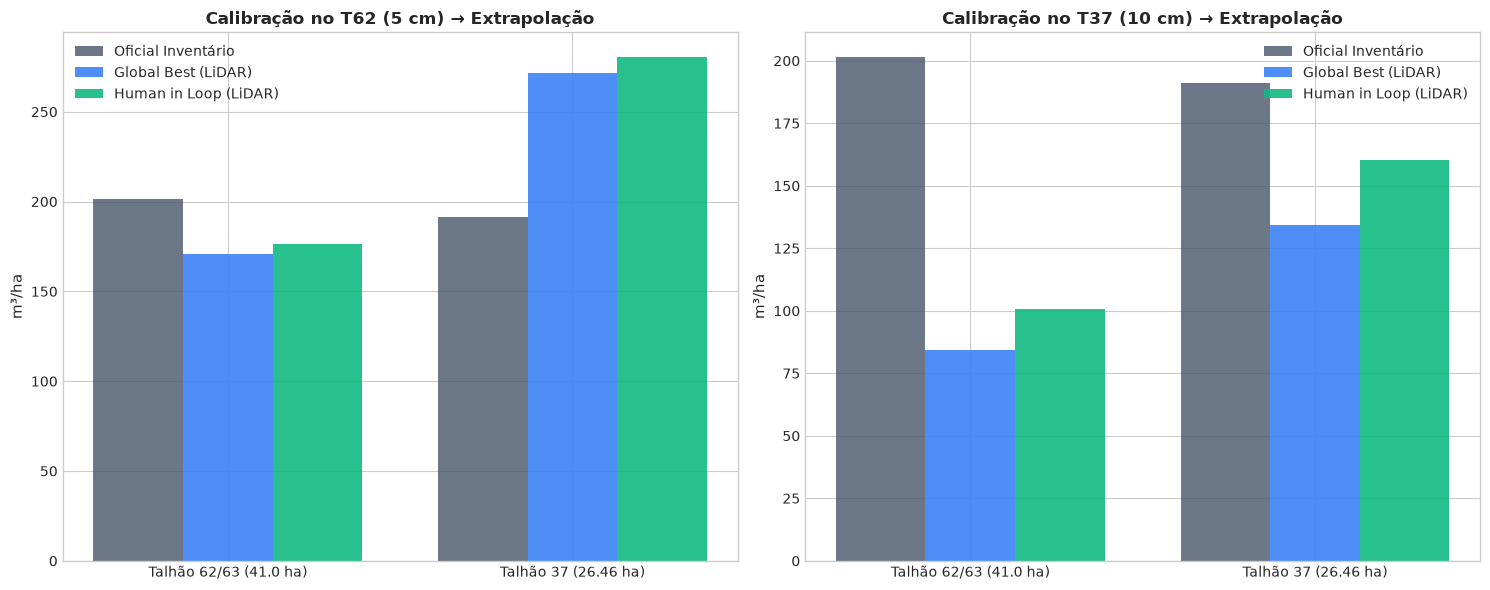

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Gráfico A: Extrapolação calibrada na base T62 (5 cm)
sub_t62 = df_extrap[df_extrap["calibration_base"].str.contains("T62")]
x_a = np.arange(len(sub_t62))
w = 0.26

axes[0].bar(x_a - w, sub_t62["gt_m3_ha"], w, label="Oficial Inventário", color="#475569", alpha=0.8)
axes[0].bar(x_a, sub_t62["global_m3_ha"], w, label="Global Best (LiDAR)", color="#3b82f6", alpha=0.9)
axes[0].bar(x_a + w, sub_t62["human_m3_ha"], w, label="Human in Loop (LiDAR)", color="#10b981", alpha=0.9)
axes[0].set_xticks(x_a)
axes[0].set_xticklabels(sub_t62["target_stand"], fontsize=10)
axes[0].set_ylabel("m³/ha", fontsize=11)
axes[0].set_title("Calibração no T62 (5 cm) → Extrapolação", fontsize=12, fontweight="bold")
axes[0].legend()

# Gráfico B: Extrapolação calibrada na base T37 (10 cm)
sub_t37 = df_extrap[df_extrap["calibration_base"].str.contains("T37")]
x_b = np.arange(len(sub_t37))
axes[1].bar(x_b - w, sub_t37["gt_m3_ha"], w, label="Oficial Inventário", color="#475569", alpha=0.8)
axes[1].bar(x_b, sub_t37["global_m3_ha"], w, label="Global Best (LiDAR)", color="#3b82f6", alpha=0.9)
axes[1].bar(x_b + w, sub_t37["human_m3_ha"], w, label="Human in Loop (LiDAR)", color="#10b981", alpha=0.9)
axes[1].set_xticks(x_b)
axes[1].set_xticklabels(sub_t37["target_stand"], fontsize=10)
axes[1].set_ylabel("m³/ha", fontsize=11)
axes[1].set_title("Calibração no T37 (10 cm) → Extrapolação", fontsize=12, fontweight="bold")
axes[1].legend()

plt.tight_layout()
plt.show()

### Tabela Síntese: Extrapolação Stand Scale (Total Timber Volume & m³/ha)

In [10]:
tab_extrap = df_extrap[["calibration_base", "target_stand", "gt_m3_ha", "global_m3_ha", "global_err_pct", "human_m3_ha", "human_err_pct", "gt_total_m3", "global_total_m3", "human_total_m3"]].copy()
tab_extrap.columns = ["Base Calibração", "Talhão Alvo", "GT (m³/ha)", "Global (m³/ha)", "Erro Global (%)", "Human (m³/ha)", "Erro Human (%)", "GT Total (m³)", "Global Total (m³)", "Human Total (m³)"]
display(tab_extrap.style.format({
    "GT (m³/ha)": "{:.1f}", "Global (m³/ha)": "{:.1f}", "Erro Global (%)": "{:+.1f}%",
    "Human (m³/ha)": "{:.1f}", "Erro Human (%)": "{:+.1f}%",
    "GT Total (m³)": "{:.1f}", "Global Total (m³)": "{:.1f}", "Human Total (m³)": "{:.1f}"
}))
print("Apresentação concluída com sucesso!")

,Base Calibração,Talhão Alvo,GT (m³/ha),Global (m³/ha),Erro Global (%),Human (m³/ha),Erro Human (%),GT Total (m³),Global Total (m³),Human Total (m³)
0,Base T62 (5cm),Talhão 62/63 (41.0 ha),201.3,170.8,-15.1%,176.1,-12.5%,8253.0,7003.9,7221.4
1,Base T62 (5cm),Talhão 37 (26.46 ha),191.1,271.8,+42.2%,280.2,+46.6%,5057.7,7191.0,7414.4
2,Base T37 (10cm),Talhão 62/63 (41.0 ha),201.3,84.5,-58.0%,100.7,-50.0%,8253.0,3462.7,4129.4
3,Base T37 (10cm),Talhão 37 (26.46 ha),191.1,134.4,-29.7%,160.2,-16.2%,5057.7,3555.2,4239.7


Apresentação concluída com sucesso!
